# CMPS 261 Project: NASA Kepler Exoplanet Classification
**Group 2:** Fatma Abu Dabos, Nadia Abou Assaly

Goal: classify Kepler Objects of Interest as confirmed exoplanets or false positives.

## 1. Setup
Libraries used in the project. The random seed is fixed so results are reproducible.

In [ ]:
import os, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Loading the data
Source: NASA Exoplanet Archive, cumulative KOI table (all columns), downloaded November 2026.

In [ ]:
# Upload koi_cumulative.csv when the file picker appears
from google.colab import files
uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]

df = pd.read_csv(CSV_PATH, low_memory=False)
print("Shape:", df.shape)
df["koi_disposition"].value_counts()

Saving koi_cumulative.csv to koi_cumulative.csv
Shape: (9564, 153)


,count
koi_disposition,
FALSE POSITIVE,4839
CONFIRMED,2748
CANDIDATE,1977


## 3. Target definition

We use koi_disposition as our target variable, which represents the classification assigned to each Kepler Object of Interest.

We retain all three categories: CONFIRMED, FALSE POSITIVE, and CANDIDATE. Each category is converted into a numerical label to make it suitable for machine learning:

CONFIRMED = 1
FALSE POSITIVE = 0
CANDIDATE = 2

We also extract kepid (Kepler ID) separately to identify which objects orbit the same star. This information will later be used for group-based train/test splitting to ensure that objects belonging to the same star do not appear in both datasets.

In [ ]:
# Keep all three classification labels
data = df[
    df["koi_disposition"].isin(
        ["CONFIRMED", "FALSE POSITIVE", "CANDIDATE"]
    )
].reset_index(drop=True)

# Target: 1 = confirmed, 0 = false positive, 2 = candidate
label_mapping = {
    "CONFIRMED": 1,
    "FALSE POSITIVE": 0,
    "CANDIDATE": 2
}

y = data["koi_disposition"].map(label_mapping).values

# Star ID, used later so the same star is never in both train and test
groups = data["kepid"].values

## 4. Data Preprocessing

We will pre process the data by removing leakage, inspecting missing values, duplicates, and outliers and then deciding how to deal with them.

## 4.1 Feature selection (leakage removal)
Some columns were created during or after the vetting process that decided the label. Using them would make the model look much better than it really is. We first check how strongly they give away the label.

In [ ]:
# Classification-related features

# 1. Compare preliminary and final dispositions
print("PRELIMINARY VS FINAL DISPOSITION")

print(pd.crosstab(
    data["koi_disposition"],
    data["koi_pdisposition"],
    normalize="index"
).round(3))


# 2. Examine Robovetter scores
print("\nKOI SCORE BY CLASS")

print(
    data.groupby("koi_disposition")["koi_score"]
    .describe()
    .round(3)
)


# 3. Examine false-positive flags
flags = [
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co",
    "koi_fpflag_ec"
]

print("\nFALSE POSITIVE FLAGS BY CLASS")

print(
    data.groupby("koi_disposition")[flags]
    .mean()
    .round(3)
)


print("KEPLER NAME AVAILABILITY BY CLASS")

print(
    data.groupby("koi_disposition")["kepler_name"]
    .apply(lambda s: s.notna().mean())
    .round(4)
)


PRELIMINARY VS FINAL DISPOSITION
koi_pdisposition  CANDIDATE  FALSE POSITIVE
koi_disposition                            
CANDIDATE             1.000           0.000
CONFIRMED             0.997           0.003
FALSE POSITIVE        0.000           1.000

KOI SCORE BY CLASS
                  count   mean    std  min    25%    50%    75%  max
koi_disposition                                                     
CANDIDATE        1377.0  0.798  0.311  0.0  0.760  0.965  0.998  1.0
CONFIRMED        2731.0  0.960  0.147  0.0  0.992  1.000  1.000  1.0
FALSE POSITIVE   3946.0  0.038  0.159  0.0  0.000  0.000  0.000  1.0

FALSE POSITIVE FLAGS BY CLASS
                 koi_fpflag_nt  koi_fpflag_ss  koi_fpflag_co  koi_fpflag_ec
koi_disposition                                                            
CANDIDATE                0.001          0.001           0.00          0.000
CONFIRMED                0.170          0.005           0.00          0.000
FALSE POSITIVE           0.315          0.457  

we remove:

- **Data leakage:** We excluded the target label (`koi_disposition`), preliminary disposition (`koi_pdisposition`), `kepler_name`, Robovetter confidence score (`koi_score`), false-positive flags, and vetting comments/status. These variables reveal or reflect the existing classification process and could allow the model to learn from NASA's previous classification rather than independent astronomical measurements.

- **Identifiers:** We excluded `kepid` and `kepoi_name` from the model's input features. However, we preserved both separately for identification purposes. The host-star ID (`kepid`) will also be used for group-based train/test splitting to ensure that objects belonging to the same star do not appear in both datasets.

- **Other features:** We initially retained the remaining columns. However, during preprocessing, we identified and excluded `koi_tce_delivname` because it is a non-numerical data-delivery metadata field rather than an astronomical measurement.

In [ ]:
# Leakage columns (classification and vetting outputs)
LEAKAGE = [
    "koi_disposition",
    "koi_pdisposition",
    "kepler_name",
    "koi_score",
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co",
    "koi_fpflag_ec",
    "koi_comment",
    "koi_vet_stat",
    "koi_vet_date",
    "koi_disp_prov"
]

# Identifiers
# kepid is saved separately in groups
IDS = ["kepid", "kepoi_name"]

# Remove only leakage columns and identifiers
columns_to_remove = LEAKAGE + IDS

# Create the feature matrix
X = data.drop(columns=columns_to_remove, errors="ignore")

X = X.drop(columns=["koi_tce_delivname"], errors="ignore")

print("Number of features kept:", X.shape[1])

Number of features kept: 138


## 4.2 Missing Values Analysis

In [ ]:
# Missing values in each feature
missing_values = pd.DataFrame({
    "Missing Values": X.isnull().sum(),
    "Missing Percentage": (X.isnull().mean() * 100).round(2)
})

# Display only columns containing missing values
missing_values = missing_values[
    missing_values["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print("Missing values per feature:")
display(missing_values)


Missing values per feature:


,Missing Values,Missing Percentage
koi_gmag_err,9564,100.00
koi_rmag_err,9564,100.00
koi_zmag_err,9564,100.00
koi_imag_err,9564,100.00
koi_kepmag_err,9564,100.00
...,...,...
koi_jmag,25,0.26
koi_kmag,25,0.26
koi_hmag,25,0.26
koi_rmag,9,0.09


In [ ]:
#first 2 features are completly empty so we will remove them

empty_columns = X.columns[X.isna().all()].tolist()

print("Completely empty columns:", empty_columns)

X = X.drop(columns=empty_columns)

print("Number of features remaining:", X.shape[1])


Completely empty columns: ['koi_gmag_err', 'koi_rmag_err', 'koi_imag_err', 'koi_zmag_err', 'koi_kepmag_err', 'koi_model_dof', 'koi_model_chisq', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_sma_err1', 'koi_sma_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_sage', 'koi_sage_err1', 'koi_sage_err2']
Number of features remaining: 114


## 4.3 Duplicate Values

In [ ]:
# Count completely duplicated rows
duplicate_count = data.duplicated().sum()

print("Number of completely duplicated rows:", duplicate_count)

# Check repeated KOI identifiers
repeated_koi = data["kepoi_name"].duplicated().sum()

print("Repeated KOI identifiers:", repeated_koi)


Number of completely duplicated rows: 0
Repeated KOI identifiers: 0


No duplicates were found, so we continue into the next step.

## 5. Train/test split (grouped by star)
Objects on the same star share identical stellar measurements, so we split by star (`kepid`) to make sure no star appears in both sets. The split is also stratified to keep the same class balance.
- 80% train: used for all tuning with 5-fold cross-validation
- 20% test: held out until the final evaluation

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Taking one fold out of 5 gives a 20% test set, grouped by star and stratified
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(X, y, groups))

X_train, y_train, g_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
X_test,  y_test,  g_test  = X.iloc[test_idx],  y[test_idx],  groups[test_idx]

# Check that no star is in both sets
assert len(set(g_train) & set(g_test)) == 0

# Display dataset sizes
print(f"Train: {len(X_train)} objects")
print(f"Test:  {len(X_test)} objects")

# Display class distribution
print("\nTraining class distribution (%):")
print(pd.Series(y_train).value_counts(normalize=True).mul(100).round(2))

print("\nTesting class distribution (%):")
print(pd.Series(y_test).value_counts(normalize=True).mul(100).round(2))


Train: 7697 objects
Test:  1867 objects

Training class distribution (%):
0    49.93
1    29.34
2    20.74
Name: proportion, dtype: float64

Testing class distribution (%):
0    53.35
1    26.25
2    20.41
Name: proportion, dtype: float64


## 6. Imputing Missing Values Using Median

In [ ]:
from sklearn.impute import SimpleImputer

# Create the imputer using the median strategy
imputer = SimpleImputer(strategy="median")

# Learn the median values from training data only
X_train_imputed = imputer.fit_transform(X_train)

# Apply the same median values to testing data
X_test_imputed = imputer.transform(X_test)

# Convert the results back to DataFrames
X_train = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

print("Remaining missing values in training:", X_train.isnull().sum().sum())
print("Remaining missing values in testing:", X_test.isnull().sum().sum())


ValueError: Cannot use median strategy with non-numeric data:
could not convert string to float: '19h27m44.22s'

## 7. Outlier Treatment and Feature Standardization

We identified highly skewed features using the training data and applied a signed log transformation to reduce the influence of extreme values without removing observations. We then used standardization to bring all features to a comparable scale, which helps Logistic Regression train more effectively. Both steps were fitted using training data only to prevent data leakage.

In [ ]:
import numpy as np
import pandas as pd

# 1. Calculate skewness using training data only
skew = X_train.skew()

# 2. Identify highly skewed features
skewed_cols = skew[abs(skew) > 2].index.tolist()

print("Highly skewed features:")
print(skewed_cols)
print(f"Number of skewed features: {len(skewed_cols)}")


# 3. Define signed log transformation
def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))


# 4. Create copies of training and testing data
X_train_log = X_train.copy()
X_test_log = X_test.copy()


# 5. Apply transformation to highly skewed features
X_train_log[skewed_cols] = signed_log(X_train_log[skewed_cols])
X_test_log[skewed_cols] = signed_log(X_test_log[skewed_cols])


# 6. Compare skewness before and after transformation
skew_comparison = pd.DataFrame({
    "Before": X_train[skewed_cols].skew(),
    "After": X_train_log[skewed_cols].skew()
})

print("\nSkewness comparison:")
print(skew_comparison.round(2))


# 7. Standardize features for Logistic Regression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_log)
X_test_scaled = scaler.transform(X_test_log)

# Convert back to DataFrames to preserve column names
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# 8. Final checks
print("\nFinal preprocessing checks:")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

## 8. Evaluation setup

- Primary metric: Macro F1-score, which balances precision and recall while giving equal importance to all three classes.
- Also reported: Accuracy, macro precision, macro recall, and ROC-AUC using a One-vs-Rest approach.
- Confusion Matrix: Used to visualize correct and incorrect classifications and identify which classes the model confuses most often.
- Accuracy is not the primary metric because the dataset is imbalanced, so overall accuracy alone may not reflect performance across all classes.
All models are evaluated using 5-fold cross-validation on the training set, grouped by host star. We report the mean and standard deviation across folds.

In [ ]:
from sklearn.metrics import confusion_matrix

# Multiclass evaluation metrics
SCORING = {
    "Accuracy": "accuracy",
    "F1": "f1_macro",
    "Precision": "precision_macro",
    "Recall": "recall_macro",
    "ROC-AUC": "roc_auc_ovr"
}

# Confusion matrix labels
CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["FALSE POSITIVE", "CONFIRMED", "CANDIDATE"]

# Store results for later comparison
results = {}

print("Evaluation metrics defined successfully!")
print(SCORING)
print("Confusion matrix will use:", CLASS_NAMES)

## 8. Level 1: Classical baselines

### 8.1 Logistic regression
Simple, interpretable reference model. We tune the regularization strength `C` and whether to reweight the classes to handle the imbalance.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict class labels
y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred = lr_model.predict(X_test_scaled)

print("Model trained successfully!")

## 8.2 Evaluate Initial Model

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
import pandas as pd

# 1. Define 5-fold grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 2. Run baseline cross-validation
baseline_cv = cross_validate(
    lr_model,
    X_train_scaled,
    y_train,
    groups=g_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True,
    n_jobs=-1
)

# 3. Calculate training and validation results
baseline_results = {}

for metric in SCORING:
    baseline_results[metric] = {
        "Training Mean": baseline_cv[f"train_{metric}"].mean(),
        "Training Std": baseline_cv[f"train_{metric}"].std(),
        "Validation Mean": baseline_cv[f"test_{metric}"].mean(),
        "Validation Std": baseline_cv[f"test_{metric}"].std()
    }

# 4. Display results
baseline_df = pd.DataFrame(baseline_results).T

print("BASELINE LOGISTIC REGRESSION - 5-FOLD CROSS-VALIDATION")
display(baseline_df.round(4))

## 8.3 Hyperparameter Tuning

In [ ]:

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Hyperparameters to test
param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "class_weight": [None, "balanced"]
}

# Define the Logistic Regression model and grid search
lr_search = GridSearchCV(

    estimator=LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid,
    scoring=SCORING,
    refit="F1",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only, keeping stars grouped
lr_search.fit(
    X_train_scaled,
    y_train,
    groups=g_train
)

# Display the best configuration
print("Best parameters:", lr_search.best_params_)
print("Best CV Macro F1:", round(lr_search.best_score_, 4))


## 8.3.1 Inspect hyperparameter search results



In [ ]:

# Extract Grid Search results
search_results = pd.DataFrame(lr_search.cv_results_)

# Select the relevant columns
results_summary = search_results[
    [
        "param_C",
        "param_penalty",
        "param_class_weight",
        "mean_train_F1",
        "std_train_F1",
        "mean_test_F1",
        "std_test_F1",
        "rank_test_F1"
    ]
].sort_values("rank_test_F1")

# Display the top 10 configurations
display(results_summary.head(10).round(4))


## 9. Baseline vs Tuned Model

In [ ]:
# Get the best tuned model
best_lr_model = lr_search.best_estimator_

# Compare baseline and tuned models
comparison = pd.DataFrame({
    "Baseline": {
        "Accuracy": baseline_cv["test_Accuracy"].mean(),
        "Macro F1": baseline_cv["test_F1"].mean(),
        "Macro Precision": baseline_cv["test_Precision"].mean(),
        "Macro Recall": baseline_cv["test_Recall"].mean(),
        "ROC-AUC": baseline_cv["test_ROC-AUC"].mean()
    },
    "Tuned Model": {
        "Accuracy": lr_search.cv_results_["mean_test_Accuracy"][lr_search.best_index_],
        "Macro F1": lr_search.cv_results_["mean_test_F1"][lr_search.best_index_],
        "Macro Precision": lr_search.cv_results_["mean_test_Precision"][lr_search.best_index_],
        "Macro Recall": lr_search.cv_results_["mean_test_Recall"][lr_search.best_index_],
        "ROC-AUC": lr_search.cv_results_["mean_test_ROC-AUC"][lr_search.best_index_]
    }
})

display(comparison.round(4))


## 10. Out-of-Fold (OOF) Evaluation

In [ ]:

from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize Logistic Regression with the best hyperparameters
oof_model = LogisticRegression(
    **lr_search.best_params_,
    solver="saga",
    max_iter=5000,
    random_state=RANDOM_STATE
)

# Generate Out-of-Fold predictions
y_oof_pred = cross_val_predict(
    oof_model,
    X_train_scaled,
    y_train,
    cv=cv,
    groups=g_train,
    method="predict",
    n_jobs=-1
)

# Display classification report
print("Out-of-Fold Classification Report:\n")
print(classification_report(
    y_train,
    y_oof_pred,
    labels=CLASS_LABELS,
    target_names=CLASS_NAMES
))

# Generate and display confusion matrix
cm_oof = confusion_matrix(
    y_train,
    y_oof_pred,
    labels=CLASS_LABELS
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=CLASS_NAMES
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - OOF Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:

import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.calibration import calibration_curve

# Generate OOF probability predictions
y_oof_proba = cross_val_predict(
    oof_model,
    X_train_scaled,
    y_train,
    cv=cv,
    groups=g_train,
    method="predict_proba",
    n_jobs=-1
)

# Convert target labels into binary format (One-vs-Rest)
y_train_binary = label_binarize(y_train, classes=CLASS_LABELS)


# ==========================================
# 1. PRECISION-RECALL CURVES
# ==========================================

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(CLASS_NAMES):

    precision, recall, _ = precision_recall_curve(
        y_train_binary[:, i],
        y_oof_proba[:, i]
    )

    avg_precision = average_precision_score(
        y_train_binary[:, i],
        y_oof_proba[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{class_name} (AP = {avg_precision:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-Fold Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("OOF_Precision_Recall_Curve.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# 2. CALIBRATION CURVES
# ==========================================

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(CLASS_NAMES):

    fraction_positive, mean_predicted = calibration_curve(
        y_train_binary[:, i],
        y_oof_proba[:, i],
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=class_name
    )

# Perfect calibration reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Out-of-Fold Calibration Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("OOF_Calibration_Curve.png", dpi=300, bbox_inches="tight")
plt.show()


## 11. Logistic Regression Coefficient Analysis

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Extract coefficients from the best tuned model
coefficients = best_lr_model.coef_

# Get feature names
feature_names = X_train.columns

# Create a coefficient DataFrame
coef_df = pd.DataFrame(
    coefficients.T,
    index=feature_names,
    columns=CLASS_NAMES
)

# Display the strongest positive and negative coefficients
for class_name in CLASS_NAMES:

    print(f"\n{'='*50}")
    print(f"{class_name}")
    print(f"{'='*50}")

    print("\nTop 10 Positive Coefficients:")
    display(
        coef_df[class_name]
        .sort_values(ascending=False)
        .head(10)
        .to_frame("Coefficient")
        .round(4)
    )

    print("\nTop 10 Negative Coefficients:")
    display(
        coef_df[class_name]
        .sort_values(ascending=True)
        .head(10)
        .to_frame("Coefficient")
        .round(4)
    )


# ==========================================
# VISUALIZE THE 10 STRONGEST COEFFICIENTS
# FOR EACH CLASS
# ==========================================

for class_name in CLASS_NAMES:

    strongest_features = (
        coef_df[class_name]
        .abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    )

    plot_data = coef_df.loc[strongest_features, class_name].sort_values()

    plt.figure(figsize=(9, 6))

    plot_data.plot(kind="barh")

    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature")
    plt.title(f"Top 10 Feature Coefficients - {class_name}")

    plt.tight_layout()
    plt.savefig(
    f"Coefficient_Analysis_{class_name.replace(' ', '_')}.png",
    dpi=300,
    bbox_inches="tight"
    )
    plt.show()


## 12. Level 2: Pretrained model (TabPFN)
TabPFN is a transformer pretrained on millions of synthetic tables. It is not trained on our data in the usual way: it reads the training rows as context and predicts new rows from them (in-context learning).
- **Why:** it is designed for small tables like ours (~6,000 rows, 47 features) and needs no hyperparameter tuning.
- **Input:** raw features. It handles missing values itself and should not be scaled.
- **Cost to watch:** "fitting" just stores the data; the real work happens at prediction, so we report prediction time too.

In [ ]:
!pip install -q tabpfn
import os, torch, tabpfn
from google.colab import userdata
os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")   # token from ux.priorlabs.ai
from tabpfn import TabPFNClassifier

print("TabPFN version:", tabpfn.__version__, "| GPU available:", torch.cuda.is_available())

In [ ]:

# Default settings, no tuning: TabPFN is pretrained

tabpfn_model = TabPFNClassifier(
    random_state=RANDOM_STATE
)

# Run grouped 5-fold cross-validation
tabpfn_cv = cross_validate(
    tabpfn_model,
    X_train,
    y_train,
    groups=g_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True,
    n_jobs=1
)

# Display prediction time
print("Prediction time / fold (s):",
      round(tabpfn_cv["score_time"].mean(), 2))

# Display evaluation results
tabpfn_results = {}

for metric in SCORING:
    tabpfn_results[metric] = {
        "Training Mean": tabpfn_cv[f"train_{metric}"].mean(),
        "Training Std": tabpfn_cv[f"train_{metric}"].std(),
        "Validation Mean": tabpfn_cv[f"test_{metric}"].mean(),
        "Validation Std": tabpfn_cv[f"test_{metric}"].std()
    }

tabpfn_df = pd.DataFrame(tabpfn_results).T

print("\nTabPFN (Pretrained) — Cross-Validation Results")
display(tabpfn_df.round(4))


In [ ]:
# Compare Logistic Regression and TabPFN fold by fold
searches = {
    "Logistic Regression": lr_search,
}

folds = pd.DataFrame({
    name: [
        s.cv_results_[f"split{i}_test_F1"][s.best_index_]
        for i in range(5)
    ]
    for name, s in searches.items()
})

folds["TabPFN"] = tabpfn_cv["test_F1"]
folds.index = [f"Fold {i+1}" for i in range(5)]

print(folds.round(4), "\n")

print(
    "TabPFN beats Logistic Regression in",
    (folds["TabPFN"] > folds["Logistic Regression"]).sum(),
    "of 5 folds"
)


In [ ]:

# Computational cost comparison: Logistic Regression vs TabPFN

cost = pd.DataFrame({
    "Settings tried": [
        len(lr_search.cv_results_["params"]),
        1
    ],

    "Total tuning time (s)": [
        lr_search.cv_results_["mean_fit_time"].sum() * 5,
        tabpfn_cv["fit_time"].sum()
    ],

    "Prediction time / fold (s)": [
        lr_search.cv_results_["mean_score_time"][
            lr_search.best_index_
        ],
        tabpfn_cv["score_time"].mean()
    ]

}, index=["Logistic Regression", "TabPFN"])

display(cost.round(2))


In [ ]:

MODELS = ["Logistic Regression", "TabPFN"]

COLOR = {
    "Logistic Regression": "#2a78d6",
    "TabPFN": "#8e44ad"
}

LABEL = {
    "Logistic Regression": "Logistic\nRegression",
    "TabPFN": "TabPFN\n(pretrained)"
}

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})


In [ ]:

fig, ax = plt.subplots(figsize=(6.5, 3.8))

x = np.arange(len(MODELS))

# Draw one line for each fold
for fold in folds.index:
    ax.plot(
        x,
        folds.loc[fold, MODELS],
        color="#d0d0d0",
        lw=1,
        zorder=1
    )

# Plot individual folds and mean scores
for j, model in enumerate(MODELS):
    ax.scatter(
        [j] * len(folds),
        folds[model],
        color=COLOR[model],
        s=35,
        zorder=2
    )

    ax.scatter(
        j,
        folds[model].mean(),
        color=COLOR[model],
        s=130,
        marker="D",
        edgecolor="white",
        linewidth=1.5,
        zorder=3
    )

    ax.text(
        j + 0.08,
        folds[model].mean(),
        f"{folds[model].mean():.3f}",
        va="center",
        fontsize=9
    )

ax.set_xticks(x, [LABEL[m] for m in MODELS])
ax.set_xlim(-0.4, 1.4)
ax.set_ylabel("Validation Macro F1")
ax.set_title("Logistic Regression vs TabPFN")
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("LR_vs_TabPFN_Fold_Comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

from sklearn.model_selection import cross_val_predict

# Generate OOF probabilities for both models
oof = {}

# Logistic Regression
oof["Logistic Regression"] = cross_val_predict(
    lr_search.best_estimator_,
    X_train_scaled,
    y_train,
    groups=g_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# TabPFN
oof["TabPFN"] = cross_val_predict(
    tabpfn_model,
    X_train,
    y_train,
    groups=g_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

print("OOF predictions generated successfully.")


In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.calibration import calibration_curve

LINE = {
    "Logistic Regression": "-.",
    "TabPFN": "--"
}

# Convert multiclass labels into one-vs-rest format
y_bin = label_binarize(y_train, classes=CLASS_LABELS)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for m in MODELS:
    probs = oof[m]

    # Micro-averaged precision-recall curve
    prec, rec, _ = precision_recall_curve(
        y_bin.ravel(), probs.ravel()
    )

    ap = average_precision_score(
        y_bin, probs, average="micro"
    )

    ax[0].plot(
        rec, prec,
        color=COLOR[m],
        ls=LINE[m],
        lw=2,
        label=f"{m} (AP = {ap:.3f})"
    )

    # Micro-averaged calibration curve
    frac_pos, mean_pred = calibration_curve(
        y_bin.ravel(),
        probs.ravel(),
        n_bins=10
    )

    ax[1].plot(
        mean_pred, frac_pos,
        color=COLOR[m],
        ls=LINE[m],
        lw=2,
        marker="o",
        ms=5,
        label=m
    )

ax[0].set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Recall",
    ylabel="Precision",
    title="(a) Precision-recall"
)

ax[1].plot(
    [0, 1], [0, 1],
    color="#999",
    lw=1,
    label="Perfect calibration"
)

ax[1].set(
    xlabel="Mean predicted probability",
    ylabel="Fraction of positives",
    title="(b) Calibration"
)

for a, loc in zip(ax, ["lower left", "upper left"]):
    a.grid(color="#e5e5e5", lw=0.8)
    a.legend(frameon=False, fontsize=8.5, loc=loc)

fig.tight_layout()
fig.savefig("fig_pr_calibration.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)

names = [LABEL[m].replace("\n", " ") for m in MODELS]

for a, col, title in zip(
    ax,
    ["Total tuning time (s)", "Prediction time / fold (s)"],
    ["(a) Tuning time (s)", "(b) Prediction time per fold (s)"]
):
    vals = cost.loc[MODELS, col]

    a.barh(
        names,
        vals,
        color=[COLOR[m] for m in MODELS],
        height=0.6
    )

    for i, v in enumerate(vals):
        a.text(
            v + vals.max() * 0.02,
            i,
            f"{v:.2f}" if v < 1 else f"{v:.0f}",
            va="center",
            fontsize=9
        )

    a.set_xlim(right=vals.max() * 1.15)
    a.set_title(title, fontsize=10)
    a.grid(axis="x", color="#e5e5e5", lw=0.8)
    a.set_axisbelow(True)

ax[0].invert_yaxis()

fig.tight_layout()
fig.savefig("fig_cost.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Final Test Evaluation and Model Comparison

FINAL TEST SET METRIC COMPARISON:


,Logistic Regression,TabPFN
Accuracy,0.7344,0.8382
F1,0.7196,0.7981
Precision,0.7172,0.8072
Recall,0.7504,0.7931
ROC-AUC,0.8931,0.9395



LOGISTIC REGRESSION - CLASSIFICATION REPORT
                precision    recall  f1-score   support

FALSE POSITIVE       0.91      0.67      0.77       987
     CONFIRMED       0.77      0.88      0.82       511
     CANDIDATE       0.47      0.70      0.56       381

      accuracy                           0.73      1879
     macro avg       0.72      0.75      0.72      1879
  weighted avg       0.78      0.73      0.74      1879


TABPFN - CLASSIFICATION REPORT
                precision    recall  f1-score   support

FALSE POSITIVE       0.87      0.91      0.89       987
     CONFIRMED       0.87      0.91      0.89       511
     CANDIDATE       0.68      0.56      0.62       381

      accuracy                           0.84      1879
     macro avg       0.81      0.79      0.80      1879
  weighted avg       0.83      0.84      0.83      1879



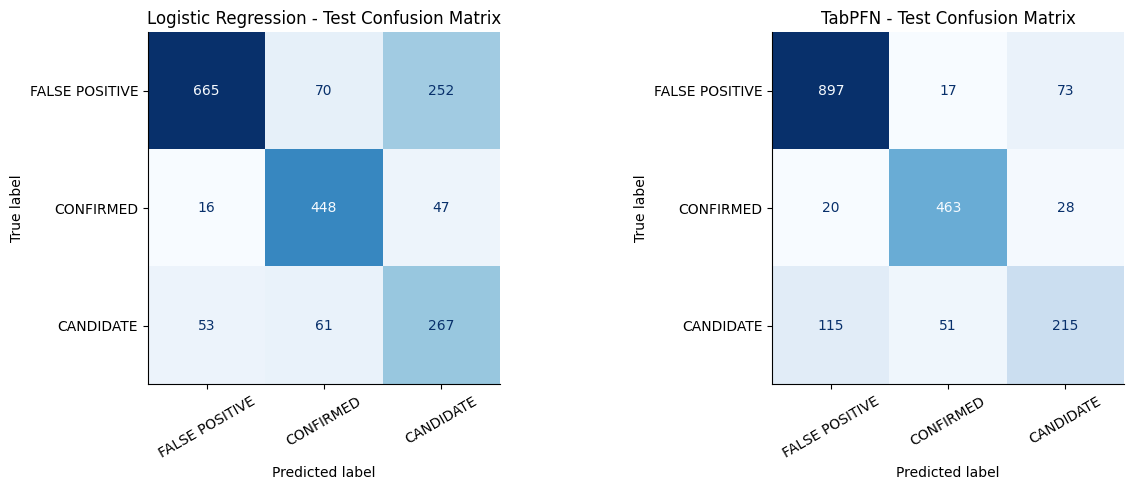

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tabpfn import TabPFNClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. LOGISTIC REGRESSION - TEST PREDICTIONS
# ==========================================

# Use the already tuned and fitted Logistic Regression model
y_pred_lr = best_lr_model.predict(X_test_scaled)
proba_lr = best_lr_model.predict_proba(X_test_scaled)


# ==========================================
# 2. TABPFN - FIT AND TEST PREDICTIONS
# ==========================================

tabpfn_final = TabPFNClassifier(
    random_state=RANDOM_STATE,
    ignore_pretraining_limits=True
)

# Fit on the full training set (unscaled features)
tabpfn_final.fit(X_train, y_train)

# Predict on the held-out test set
y_pred_tabpfn = tabpfn_final.predict(X_test)
proba_tabpfn = tabpfn_final.predict_proba(X_test)


# ==========================================
# 3. ALIGN PROBABILITIES WITH CLASS LABELS
# ==========================================

def align_probabilities(model, probabilities):
    return probabilities[:, [
        list(model.classes_).index(label)
        for label in CLASS_LABELS
    ]]

proba_lr = align_probabilities(best_lr_model, proba_lr)
proba_tabpfn = align_probabilities(tabpfn_final, proba_tabpfn)


# ==========================================
# 4. CALCULATE THE FIVE EVALUATION METRICS
# ==========================================

def evaluate_model(y_true, y_pred, y_proba):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "F1": f1_score(
            y_true, y_pred, average="macro"
        ),

        "Precision": precision_score(
            y_true, y_pred, average="macro"
        ),

        "Recall": recall_score(
            y_true, y_pred, average="macro"
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_proba,
            labels=CLASS_LABELS,
            multi_class="ovr",
            average="macro"
        )
    }


lr_test_results = evaluate_model(
    y_test, y_pred_lr, proba_lr
)

tabpfn_test_results = evaluate_model(
    y_test, y_pred_tabpfn, proba_tabpfn
)


# ==========================================
# 5. COMPARE BOTH MODELS
# ==========================================

test_comparison = pd.DataFrame(
    {
        "Logistic Regression": lr_test_results,
        "TabPFN": tabpfn_test_results
    }
)

print("FINAL TEST SET METRIC COMPARISON:")
display(test_comparison.round(4))


# ==========================================
# 6. CLASSIFICATION REPORTS
# ==========================================

print("\nLOGISTIC REGRESSION - CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred_lr,
    labels=CLASS_LABELS,
    target_names=CLASS_NAMES
))

print("\nTABPFN - CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred_tabpfn,
    labels=CLASS_LABELS,
    target_names=CLASS_NAMES
))


# ==========================================
# 7. CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, predictions, model_name in zip(
    axes,
    [y_pred_lr, y_pred_tabpfn],
    ["Logistic Regression", "TabPFN"]
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=CLASS_LABELS
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Test Confusion Matrix")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(
    "Final_Test_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

files.download("Final_Test_Confusion_Matrices.png")


## 14. Failure Analysis

We investigate where Logistic Regression and TabPFN make mistakes,
rather than relying only on aggregate classification metrics.

We analyze four potential failure modes:
1. Weak transit signals (low signal-to-noise ratio).
2. Differences in host-star temperature.
3. Observations with missing measurements.
4. Confusion between unresolved candidates and false positives.

All analyses use the existing held-out test predictions.
No additional model training is performed.

Test observations: 1879
Missing-value groups:


,count
missing_group,
No missing values,1724
Has missing values,155



A. FAILURE ANALYSIS BY TRANSIT SNR


,Group,Model,N,Error Rate,Macro F1,Candidate N,Candidate Recall
0,"(-inf, 12.0]",Logistic Regression,465,0.424,0.466,231,0.896
1,"(-inf, 12.0]",TabPFN,465,0.265,0.618,231,0.749
2,"(12.0, 23.0]",Logistic Regression,434,0.336,0.632,84,0.512
3,"(12.0, 23.0]",TabPFN,434,0.219,0.709,84,0.357
4,"(23.0, 78.3]",Logistic Regression,454,0.161,0.637,29,0.138
5,"(23.0, 78.3]",TabPFN,454,0.097,0.690,29,0.138
6,"(78.3, inf]",Logistic Regression,447,0.094,0.619,18,0.056
7,"(78.3, inf]",TabPFN,447,0.051,0.712,18,0.167



B. FAILURE ANALYSIS BY STELLAR TEMPERATURE


,Group,Model,N,Error Rate,Macro F1,Candidate N,Candidate Recall
0,"(-inf, 5297.0]",Logistic Regression,403,0.285,0.699,82,0.671
1,"(-inf, 5297.0]",TabPFN,403,0.169,0.786,82,0.500
2,"(5297.0, 5766.0]",Logistic Regression,486,0.226,0.754,103,0.699
3,"(5297.0, 5766.0]",TabPFN,486,0.148,0.819,103,0.602
4,"(5766.0, 6109.0]",Logistic Regression,448,0.250,0.739,98,0.714
5,"(5766.0, 6109.0]",TabPFN,448,0.172,0.801,98,0.633
6,"(6109.0, inf]",Logistic Regression,463,0.261,0.687,79,0.734
7,"(6109.0, inf]",TabPFN,463,0.147,0.782,79,0.570



C. FAILURE ANALYSIS BY MISSINGNESS


,Group,Model,N,Error Rate,Macro F1,Candidate N,Candidate Recall
0,Has missing values,Logistic Regression,155,0.510,0.424,31,0.613
1,Has missing values,TabPFN,155,0.213,0.685,31,0.323
2,No missing values,Logistic Regression,1724,0.244,0.739,350,0.709
3,No missing values,TabPFN,1724,0.157,0.805,350,0.586



D. CANDIDATE FAILURE ANALYSIS


,Model,Actual Candidates,Correct Candidates,Candidates Predicted False Positive,Candidates Predicted Confirmed,Candidate Recall,False Positives Predicted Candidate
0,Logistic Regression,381,267,53,61,0.701,252
1,TabPFN,381,215,115,51,0.564,73


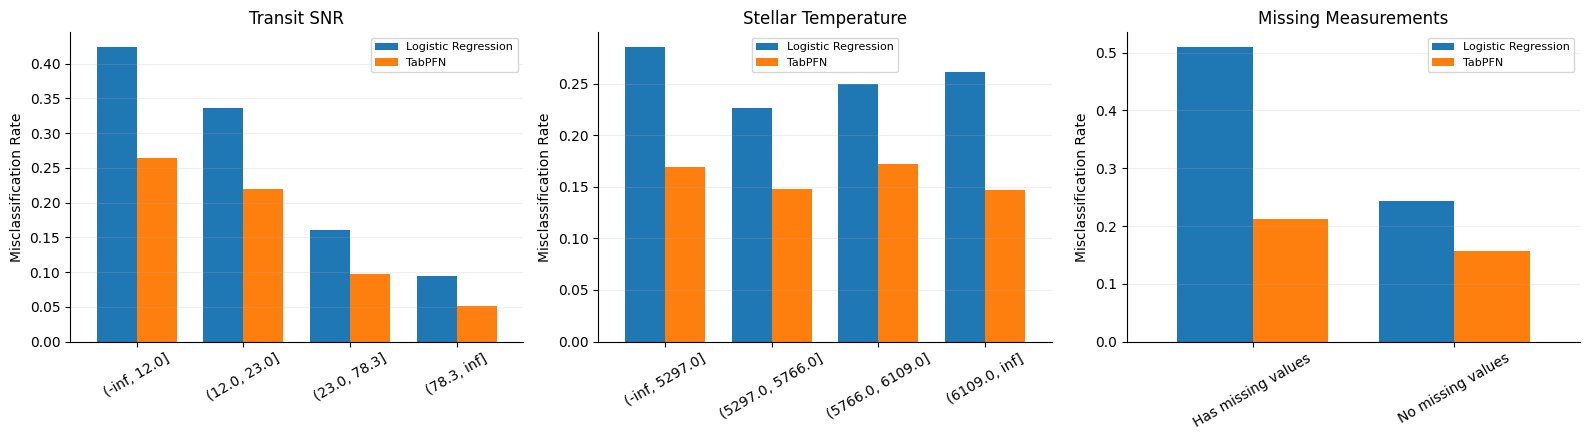


Failure analysis completed!
Figure saved as failure_analysis.png


In [49]:
# ============================================================
# STEP 14: FAILURE ANALYSIS ON THE HELD-OUT TEST SET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score, recall_score
from IPython.display import display

# ------------------------------------------------------------
# 1. Reuse predictions from Step 13
# ------------------------------------------------------------

y_true = np.asarray(y_test)

predictions = {
    "Logistic Regression": np.asarray(y_pred_lr),
    "TabPFN": np.asarray(y_pred_tabpfn)
}

# IMPORTANT:
# X_test has already been imputed.
# X.iloc[test_idx] contains the original missing values.

X_test_original = X.iloc[test_idx].copy()

assert len(X_test_original) == len(y_true)

analysis = X_test_original.copy()
analysis["actual"] = y_true

for name, pred in predictions.items():
    analysis[f"{name}_pred"] = pred
    analysis[f"{name}_correct"] = (pred == y_true)

# Original missingness, before median imputation
analysis["missing_count"] = (
    X_test_original.isna().sum(axis=1)
)

analysis["missing_group"] = np.where(
    analysis["missing_count"] > 0,
    "Has missing values",
    "No missing values"
)

print("Test observations:", len(analysis))
print("Missing-value groups:")
display(analysis["missing_group"].value_counts())


# ------------------------------------------------------------
# 2. Define a reusable subgroup evaluation function
# ------------------------------------------------------------

def evaluate_groups(group_col):

    rows = []

    for group_name, subset in analysis.groupby(
        group_col, observed=True
    ):

        indices = analysis.index.get_indexer(
            subset.index
        )

        true = y_true[indices]

        for model_name, pred in predictions.items():

            predicted = pred[indices]

            candidate_mask = (true == 2)

            candidate_recall = (
                recall_score(
                    true[candidate_mask],
                    predicted[candidate_mask],
                    labels=[2],
                    average="macro",
                    zero_division=0
                )
                if candidate_mask.sum() > 0
                else np.nan
            )

            rows.append({
                "Group": str(group_name),
                "Model": model_name,
                "N": len(true),
                "Error Rate": np.mean(
                    true != predicted
                ),
                "Macro F1": f1_score(
                    true,
                    predicted,
                    labels=CLASS_LABELS,
                    average="macro",
                    zero_division=0
                ),
                "Candidate N": candidate_mask.sum(),
                "Candidate Recall": candidate_recall
            })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 3. Failure mode A: Transit signal strength
# ------------------------------------------------------------

# koi_model_snr measures transit signal-to-noise.
# Quantile groups are defined from TRAINING data only.

def training_quantile_bins(column):

    train_values = pd.to_numeric(
        X.iloc[train_idx][column],
        errors="coerce"
    ).dropna()

    edges = np.unique(
        np.quantile(train_values, [0, .25, .5, .75, 1])
    )

    edges[0] = -np.inf
    edges[-1] = np.inf

    return edges


if "koi_model_snr" in analysis.columns:

    snr_edges = training_quantile_bins(
        "koi_model_snr"
    )

    analysis["snr_group"] = pd.cut(
        analysis["koi_model_snr"],
        bins=snr_edges,
        include_lowest=True
    )

    snr_results = evaluate_groups("snr_group")

    print("\nA. FAILURE ANALYSIS BY TRANSIT SNR")
    display(snr_results.round(3))

else:
    print("koi_model_snr not available.")


# ------------------------------------------------------------
# 4. Failure mode B: Host-star temperature
# ------------------------------------------------------------

if "koi_steff" in analysis.columns:

    temp_edges = training_quantile_bins(
        "koi_steff"
    )

    analysis["temperature_group"] = pd.cut(
        analysis["koi_steff"],
        bins=temp_edges,
        include_lowest=True
    )

    temperature_results = evaluate_groups(
        "temperature_group"
    )

    print("\nB. FAILURE ANALYSIS BY STELLAR TEMPERATURE")
    display(temperature_results.round(3))

else:
    print("koi_steff not available.")


# ------------------------------------------------------------
# 5. Failure mode C: Missing measurements
# ------------------------------------------------------------

missing_results = evaluate_groups("missing_group")

print("\nC. FAILURE ANALYSIS BY MISSINGNESS")
display(missing_results.round(3))


# ------------------------------------------------------------
# 6. Failure mode D: Candidate confusion
# ------------------------------------------------------------

candidate_mask = (y_true == 2)

candidate_rows = []

for model_name, pred in predictions.items():

    candidate_rows.append({
        "Model": model_name,
        "Actual Candidates": candidate_mask.sum(),
        "Correct Candidates": np.sum(
            candidate_mask & (pred == 2)
        ),
        "Candidates Predicted False Positive": np.sum(
            candidate_mask & (pred == 0)
        ),
        "Candidates Predicted Confirmed": np.sum(
            candidate_mask & (pred == 1)
        ),
        "Candidate Recall": np.mean(
            pred[candidate_mask] == 2
        ),
        "False Positives Predicted Candidate": np.sum(
            (y_true == 0) & (pred == 2)
        )
    })

candidate_results = pd.DataFrame(candidate_rows)

print("\nD. CANDIDATE FAILURE ANALYSIS")
display(candidate_results.round(3))


# ------------------------------------------------------------
# 7. Plot subgroup error rates
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5)
)

datasets = [
    (snr_results, "Transit SNR"),
    (temperature_results, "Stellar Temperature"),
    (missing_results, "Missing Measurements")
]

for ax, (df, title) in zip(axes, datasets):

    pivot = df.pivot(
        index="Group",
        columns="Model",
        values="Error Rate"
    )

    pivot.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title(title)
    ax.set_ylabel("Misclassification Rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    "failure_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFailure analysis completed!")
print("Figure saved as failure_analysis.png")

## 14. Cell To Download the Files

In [50]:
import os
import zipfile
from google.colab import files

# Create a folder for the figures
figures_folder = "figures"

# Create ZIP file
zip_filename = "project_figures.zip"

image_extensions = (".png", ".jpg", ".jpeg", ".pdf", ".svg")

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:

    for filename in os.listdir("."):
        if filename.lower().endswith(image_extensions):
            zipf.write(filename, arcname=filename)

print("All figures have been added to the ZIP file!")

# Download ZIP automatically
files.download(zip_filename)

All figures have been added to the ZIP file!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
from google.colab import files

# Save Logistic Regression
lr_final = lr_search.best_estimator_
joblib.dump(lr_final, "logistic_regression_model.pkl")

# Save TabPFN
joblib.dump(tabpfn_model, "tabpfn_model.pkl")

# Save preprocessing information
preprocessing = {
    "scaler": scaler,
    "imputer": imputer,
    "feature_names": X_train.columns.tolist(),
    "skewed_columns": skewed_cols,
    "class_labels": CLASS_LABELS,
    "class_names": CLASS_NAMES
}

joblib.dump(preprocessing, "preprocessing.pkl")

print("Both models and preprocessing saved successfully!")

files.download("logistic_regression_model.pkl")
files.download("tabpfn_model.pkl")
files.download("preprocessing.pkl")